In [1]:
#importing required libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [2]:
#loading the emergency department data
imported_data = pd.read_excel(r"C:\Users\user\OneDrive\Documents\ZION TECH HUB CAPSTONE\ED_Waiting_Time_Data.xlsx")

In [3]:
#viewing the data
imported_data.head()

,patient_id,visit_date,day_of_week,day_type,season,arrival_time,arrival_hour,department,triage_priority,chief_complaint,age,gender,staff_on_duty,patients_in_queue_at_arrival,registration_time_minutes,triage_time_minutes,wait_time_to_provider_minutes,consultation_duration_minutes,total_visit_duration_minutes
0,PT00001,2025-01-25,Saturday,Weekend,Harmattan/Dry,12:46:00,12,Maternity,4,Sprain,9,Male,9,6,4.3,9.1,46.8,12.9,73.1
1,PT00002,2025-07-09,Wednesday,Weekday,Peak Rainy,22:21:00,22,Maternity,4,Back pain,43,Male,8,3,4.4,9.8,33.1,9.1,56.4
2,PT00003,2025-06-02,Monday,Weekday,Peak Rainy,12:40:00,12,Maternity,4,Minor laceration,17,Male,12,3,6.1,8.9,25.6,11.2,51.8
3,PT00004,2025-05-17,Saturday,Weekend,Early Rainy,08:34:00,8,Emergency,4,Back pain,6,Male,10,4,7.7,7.4,47.2,17.0,79.3
4,PT00005,2025-09-05,Friday,Weekday,Peak Rainy,17:17:00,17,Outpatient - General,4,UTI symptoms,23,Female,11,2,7.0,6.6,56.4,18.0,88.0


In [4]:
imported_data.tail()

,patient_id,visit_date,day_of_week,day_type,season,arrival_time,arrival_hour,department,triage_priority,chief_complaint,age,gender,staff_on_duty,patients_in_queue_at_arrival,registration_time_minutes,triage_time_minutes,wait_time_to_provider_minutes,consultation_duration_minutes,total_visit_duration_minutes
5995,PT05996,2025-09-05,Friday,Weekday,Peak Rainy,09:05:00,9,Pediatrics,4,Back pain,25,Male,11,6,4.5,10.3,49.6,10.5,74.9
5996,PT05997,2025-03-01,Saturday,Weekend,Early Rainy,07:29:00,7,Outpatient - General,4,Back pain,52,Male,3,6,7.8,14.7,84.4,5.8,112.7
5997,PT05998,2025-08-06,Wednesday,Weekday,Peak Rainy,10:40:00,10,Emergency,4,UTI symptoms,24,Female,11,9,6.1,11.5,60.4,13.4,91.4
5998,PT05999,2025-07-13,Sunday,Weekend,Peak Rainy,11:44:00,11,Surgery Referral,2,Severe bleeding,19,Male,7,2,3.4,10.0,2.1,20.8,36.4
5999,PT06000,2025-07-07,Monday,Weekday,Peak Rainy,11:17:00,11,Maternity,4,Minor laceration,95,Male,12,3,5.3,7.5,27.5,16.5,56.7


In [5]:
imported_data.sample(10)

,patient_id,visit_date,day_of_week,day_type,season,arrival_time,arrival_hour,department,triage_priority,chief_complaint,age,gender,staff_on_duty,patients_in_queue_at_arrival,registration_time_minutes,triage_time_minutes,wait_time_to_provider_minutes,consultation_duration_minutes,total_visit_duration_minutes
406,PT00407,2025-02-15,Saturday,Weekend,Harmattan/Dry,09:18:00,9,Outpatient - General,5,Prescription refill,8,Female,10,9,5.6,4.1,99.3,6.2,115.2
5911,PT05912,2025-07-06,Sunday,Weekend,Peak Rainy,17:06:00,17,Outpatient - General,5,Prescription refill,56,Male,10,7,8.9,10.7,96.2,20.1,135.9
2358,PT02359,2025-09-16,Tuesday,Weekday,Peak Rainy,14:07:00,14,Outpatient - General,4,UTI symptoms,12,Male,10,3,4.4,5.4,65.8,19.6,95.2
972,PT00973,2025-05-02,Friday,Weekday,Early Rainy,11:38:00,11,Emergency,4,Mild fever,41,Male,12,4,7.2,8.9,47.6,16.7,80.4
2421,PT02422,2025-08-21,Thursday,Weekday,Peak Rainy,21:41:00,21,Pediatrics,3,High fever,18,Female,7,5,5.0,5.8,15.7,13.3,39.8
5453,PT05454,2025-02-19,Wednesday,Weekday,Harmattan/Dry,20:52:00,20,Outpatient - General,3,Asthma exacerbation,84,Male,10,5,6.3,8.0,36.3,6.4,57.1
594,PT00595,2025-01-10,Friday,Weekday,Harmattan/Dry,10:06:00,10,Emergency,3,Abdominal pain,2,Male,11,6,7.6,11.2,30.6,12.9,62.3
139,PT00140,2025-09-21,Sunday,Weekend,Peak Rainy,18:58:00,18,Outpatient - General,3,Asthma exacerbation,5,Female,11,9,4.0,12.5,58.9,17.8,93.2
5526,PT05527,2025-06-10,Tuesday,Weekday,Peak Rainy,11:38:00,11,Pediatrics,4,Minor laceration,5,Female,10,1,4.7,10.5,37.4,14.0,66.7
3513,PT03514,2025-06-26,Thursday,Weekday,Peak Rainy,08:37:00,8,Outpatient - General,4,Sprain,45,Female,11,3,7.1,7.6,52.6,20.0,87.3


In [6]:
#exploring the data
imported_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 19 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   patient_id                     6000 non-null   object        
 1   visit_date                     6000 non-null   datetime64[ns]
 2   day_of_week                    6000 non-null   object        
 3   day_type                       6000 non-null   object        
 4   season                         6000 non-null   object        
 5   arrival_time                   6000 non-null   object        
 6   arrival_hour                   6000 non-null   int64         
 7   department                     6000 non-null   object        
 8   triage_priority                6000 non-null   int64         
 9   chief_complaint                5880 non-null   object        
 10  age                            6000 non-null   int64         
 11  gender           

##### There are 6000 rows (patient visits) and 19 columns (6 are date/time-related, 4 describe the patient while 9 are hospital-related). 

##### Triage priority colum should be stored as an object column (string) because it is categorical data and not numerical.

In [7]:
data = imported_data.copy()

In [8]:
data['triage_priority'] = data['triage_priority'].astype(str)

In [9]:
data.describe()

,visit_date,arrival_hour,age,staff_on_duty,patients_in_queue_at_arrival,registration_time_minutes,triage_time_minutes,wait_time_to_provider_minutes,consultation_duration_minutes,total_visit_duration_minutes
count,6000,6000.00000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,2025-05-13 22:18:57.600000,13.43700,33.718500,10.165333,5.270167,5.986750,8.065117,42.044583,14.867183,70.964050
min,2025-01-01 00:00:00,0.00000,0.000000,3.000000,0.000000,1.000000,2.000000,0.000000,5.000000,15.100000
25%,2025-03-08 00:00:00,9.00000,17.000000,9.000000,3.000000,4.600000,6.000000,25.700000,10.500000,54.600000
50%,2025-05-12 00:00:00,13.00000,29.000000,11.000000,5.000000,6.000000,8.100000,42.600000,14.700000,71.150000
75%,2025-07-19 00:00:00,18.00000,46.000000,12.000000,7.000000,7.300000,10.100000,58.900000,18.900000,87.200000
max,2025-09-27 00:00:00,23.00000,95.000000,16.000000,20.000000,12.700000,19.000000,115.500000,40.000000,145.200000
std,NaN,5.16383,21.963591,2.357242,3.155604,1.993609,2.931422,23.039124,5.903230,23.036002


##### The data spans from 1st January 2025 to 27th September 2025 (about 9 months).

In [10]:
data.describe(include='object')

,patient_id,day_of_week,day_type,season,arrival_time,department,triage_priority,chief_complaint,gender
count,6000,6000,6000,6000,6000,6000,6000,5880,6000
unique,6000,7,2,3,1237,5,5,23,2
top,PT00001,Monday,Weekday,Peak Rainy,19:49:00,Emergency,4,Back pain,Male
freq,1,920,4351,2581,16,2087,2133,437,3002


In [11]:
#checking for missing values
data.isnull().sum()

patient_id                         0
visit_date                         0
day_of_week                        0
day_type                           0
season                             0
arrival_time                       0
arrival_hour                       0
department                         0
triage_priority                    0
chief_complaint                  120
age                                0
gender                             0
staff_on_duty                      0
patients_in_queue_at_arrival       0
registration_time_minutes          0
triage_time_minutes                0
wait_time_to_provider_minutes      0
consultation_duration_minutes      0
total_visit_duration_minutes       0
dtype: int64

##### Chief complaint is the only column with missing data.

In [12]:
missing_cc_dept = data[data['chief_complaint'].isnull()]['department'].value_counts().sort_values(ascending=False)
missing_cc_dept

department
Emergency               41
Outpatient - General    38
Surgery Referral        17
Pediatrics              16
Maternity                8
Name: count, dtype: int64

In [13]:
missing_cc_triage = data[data['chief_complaint'].isnull()]['triage_priority'].value_counts().sort_values(ascending=False)
missing_cc_triage

triage_priority
4    52
3    34
5    18
2    13
1     3
Name: count, dtype: int64

##### To avoid losing patient data, these 120 missing values will be imputed using a placeholder 'Not specified'.

In [14]:
data['chief_complaint'] = data['chief_complaint'].fillna('Not specified')

In [15]:
data.isnull().sum()

patient_id                       0
visit_date                       0
day_of_week                      0
day_type                         0
season                           0
arrival_time                     0
arrival_hour                     0
department                       0
triage_priority                  0
chief_complaint                  0
age                              0
gender                           0
staff_on_duty                    0
patients_in_queue_at_arrival     0
registration_time_minutes        0
triage_time_minutes              0
wait_time_to_provider_minutes    0
consultation_duration_minutes    0
total_visit_duration_minutes     0
dtype: int64

##### The data looks clean.

In [16]:
data['patient_id'].duplicated().sum()

0

In [17]:
#checking data consistency
data[data['day_of_week'].str.startswith('S')]['day_type'].unique()

array(['Weekend'], dtype=object)

In [18]:
data[~data['day_of_week'].str.startswith('S')]['day_type'].unique()

array(['Weekday'], dtype=object)

### UNIVARIATE EDA

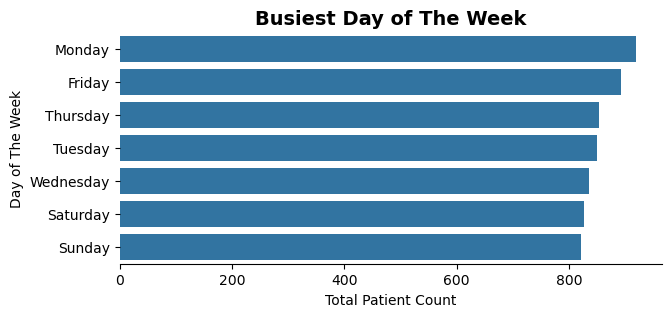

In [19]:
#most frequently visited day of the week
plt.figure(figsize=(7,3))
sns.countplot(data=data, y='day_of_week', order=data['day_of_week'].value_counts().index)
plt.title('Busiest Day of The Week', fontsize=14, fontweight='bold')
plt.xlabel('Total Patient Count')
plt.ylabel('Day of The Week')
sns.despine(left=True, top=True, right=True)
plt.show()

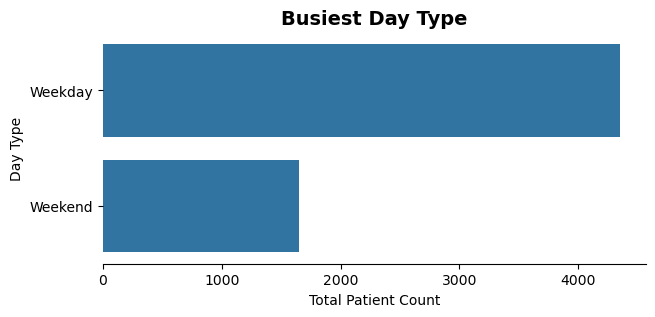

In [20]:
plt.figure(figsize=(7,3))
sns.countplot(data=data, y='day_type', order=data['day_type'].value_counts().index)
plt.title('Busiest Day Type', fontsize=14, fontweight='bold')
plt.xlabel('Total Patient Count')
plt.ylabel('Day Type')
sns.despine(left=True, top=True, right=True)
plt.show()

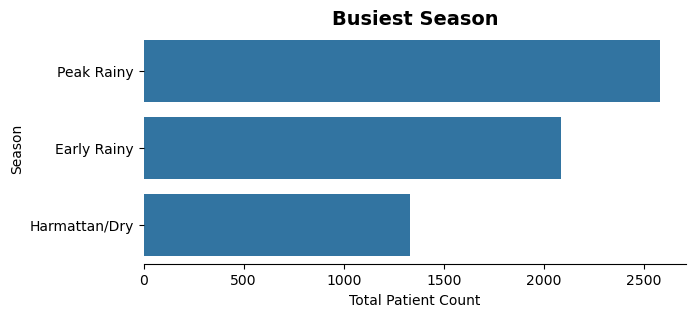

In [21]:
plt.figure(figsize=(7,3))
sns.countplot(data=data, y='season', order=data['season'].value_counts().index)
plt.title('Busiest Season', fontsize=14, fontweight='bold')
plt.xlabel('Total Patient Count')
plt.ylabel('Season')
sns.despine(left=True, top=True, right=True)
plt.show()

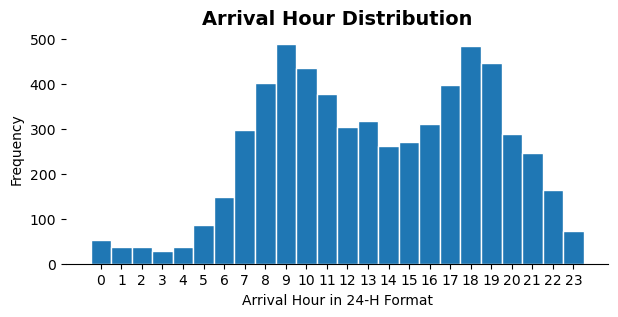

In [22]:
plt.figure(figsize=(7,3))
min_val = data['arrival_hour'].min()
max_val = data['arrival_hour'].max()
bins = np.arange(min_val-0.5,max_val+1.5, 1)
plt.hist(data=data, x='arrival_hour',bins=bins,edgecolor='white')
plt.title('Arrival Hour Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Arrival Hour in 24-H Format')
plt.ylabel('Frequency')
plt.xticks(range(min_val, max_val+1, 1))
sns.despine(left=True, top=True, right=True)
plt.show()

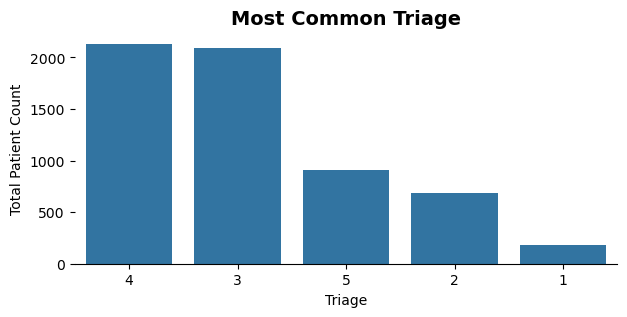

In [23]:
plt.figure(figsize=(7,3))
sns.countplot(data=data, x='triage_priority')
plt.title('Most Common Triage', fontsize=14, fontweight='bold')
plt.ylabel('Total Patient Count')
plt.xlabel('Triage')
sns.despine(left=True, top=True, right=True)
plt.show()

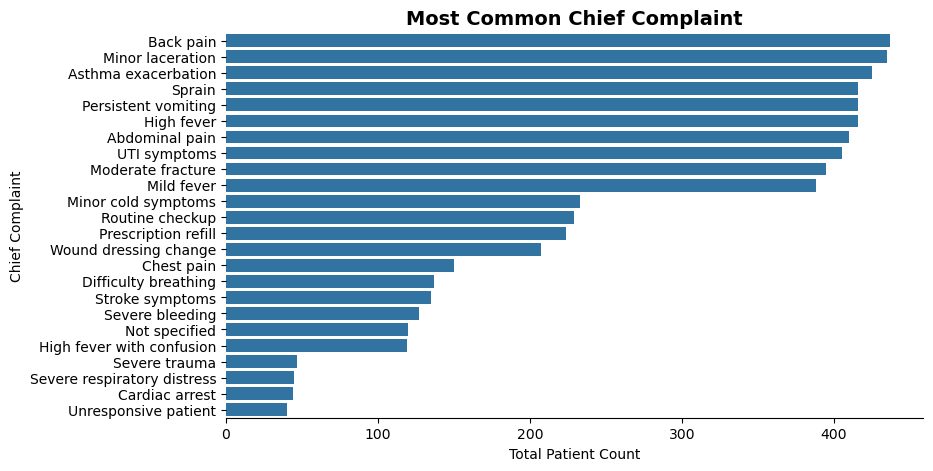

In [24]:
plt.figure(figsize=(9,5))
sns.countplot(data=data, y='chief_complaint', order=data['chief_complaint'].value_counts().index)
plt.title('Most Common Chief Complaint', fontsize=14, fontweight='bold')
plt.xlabel('Total Patient Count')
plt.ylabel('Chief Complaint')
sns.despine(left=True, top=True, right=True)
plt.show()

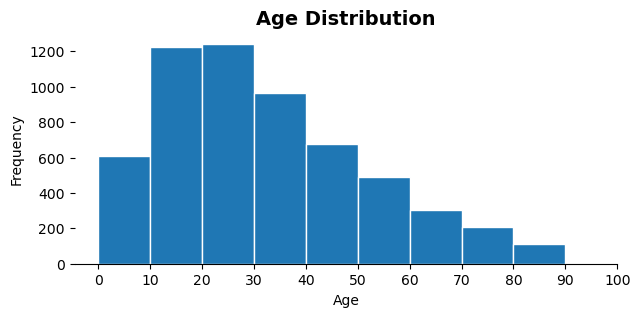

In [25]:
plt.figure(figsize=(7,3))
min_val = data['age'].min()
max_val = data['age'].max()
bins = np.arange(min_val,max_val, 10)
plt.hist(data=data, x='age',bins=bins,edgecolor='white')
plt.title("Age Distribution", fontsize=14, fontweight='bold')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.xticks(range(min_val, max_val+10, 10))
sns.despine(left=True, top=True, right=True)
plt.show()

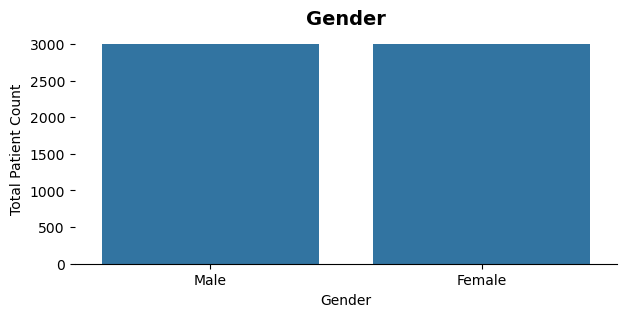

In [26]:
plt.figure(figsize=(7,3))
sns.countplot(data=data, x='gender', order=data['gender'].value_counts().index)
plt.title('Gender', fontsize=14, fontweight='bold')
plt.ylabel('Total Patient Count')
plt.xlabel('Gender')
sns.despine(left=True, top=True, right=True)
plt.show()

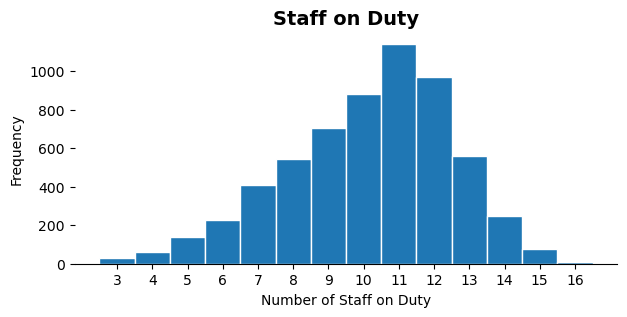

In [27]:
plt.figure(figsize=(7,3))
min_val = data['staff_on_duty'].min()
max_val = data['staff_on_duty'].max()
bins = np.arange(min_val-0.5,max_val+1.5, 1)
plt.hist(data=data, x='staff_on_duty',bins=bins, edgecolor='white')
plt.title("Staff on Duty", fontsize=14, fontweight='bold')
plt.xlabel('Number of Staff on Duty')
plt.ylabel('Frequency')
plt.xticks(range(min_val, max_val+1))
sns.despine(left=True, top=True, right=True)
plt.show()

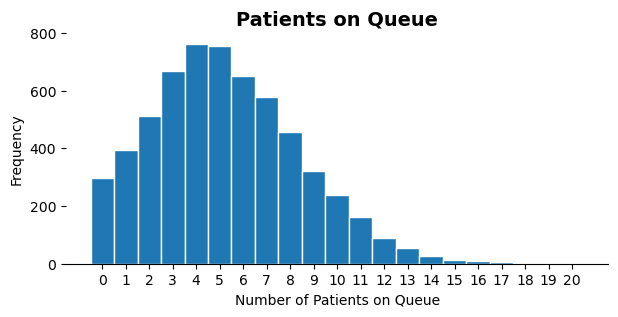

In [28]:
plt.figure(figsize=(7,3))
min_val = data['patients_in_queue_at_arrival'].min()
max_val = data['patients_in_queue_at_arrival'].max()
bins = np.arange(min_val-0.5,max_val+1.5, 1)
plt.hist(data=data, x='patients_in_queue_at_arrival',bins=bins, edgecolor='white')
plt.title("Patients on Queue", fontsize=14, fontweight='bold')
plt.xlabel('Number of Patients on Queue')
plt.ylabel('Frequency')
plt.xticks(range(min_val, max_val+1))
sns.despine(left=True, top=True, right=True)
plt.show()

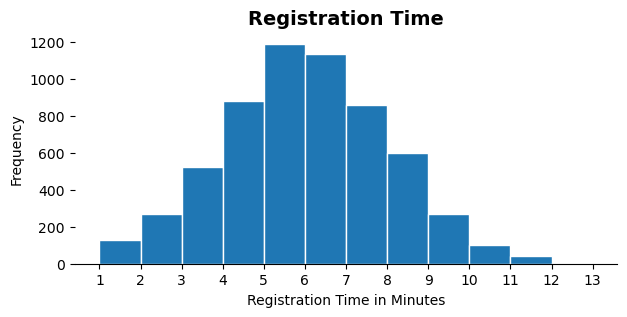

In [29]:
plt.figure(figsize=(7,3))
min_val = data['registration_time_minutes'].min()
max_val = data['registration_time_minutes'].max()
bins = np.arange(min_val,max_val+1, 1)
plt.hist(data=data, x='registration_time_minutes',bins=bins, edgecolor='white')
plt.title("Registration Time", fontsize=14, fontweight='bold')
plt.xlabel('Registration Time in Minutes')
plt.ylabel('Frequency')
plt.xticks(bins)
sns.despine(left=True, top=True, right=True)
plt.show()

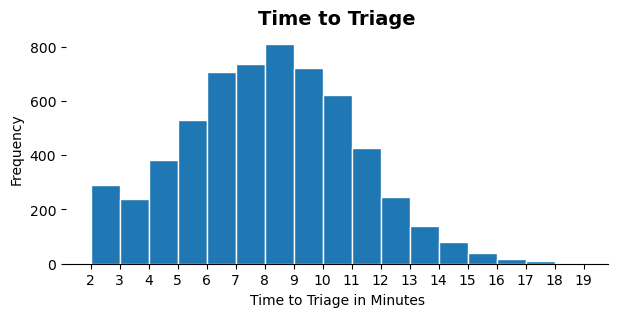

In [30]:
plt.figure(figsize=(7,3))
min_val = data['triage_time_minutes'].min()
max_val = data['triage_time_minutes'].max()
bins = np.arange(min_val,max_val+1, 1)
plt.hist(data=data, x='triage_time_minutes',bins=bins, edgecolor='white')
plt.title("Time to Triage", fontsize=14, fontweight='bold')
plt.xlabel('Time to Triage in Minutes')
plt.ylabel('Frequency')
plt.xticks(bins)
sns.despine(left=True, top=True, right=True)
plt.show()

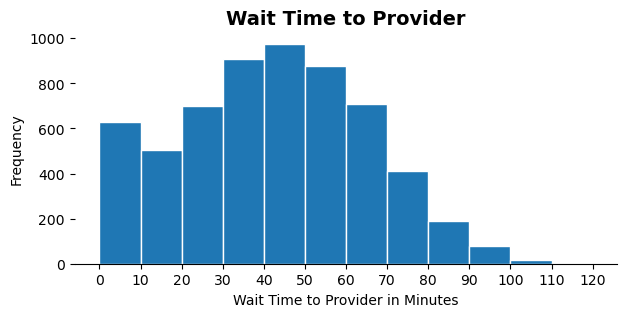

In [31]:
plt.figure(figsize=(7,3))
min_val = data['wait_time_to_provider_minutes'].min()
max_val = data['wait_time_to_provider_minutes'].max()
bins = np.arange(min_val,max_val+10, 10)
plt.hist(data=data, x='wait_time_to_provider_minutes',bins=bins, edgecolor='white')
plt.title("Wait Time to Provider", fontsize=14, fontweight='bold')
plt.xlabel('Wait Time to Provider in Minutes')
plt.ylabel('Frequency')
plt.xticks(bins)
sns.despine(left=True, top=True, right=True)
plt.show()

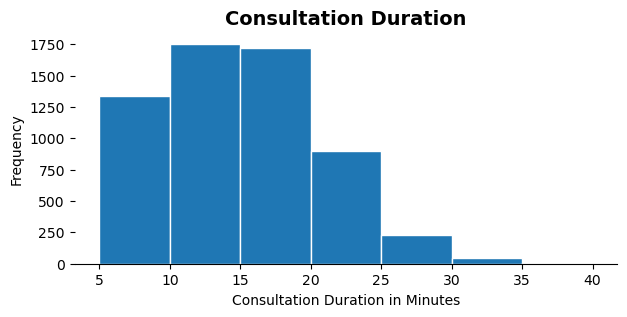

In [32]:
plt.figure(figsize=(7,3))
min_val = data['consultation_duration_minutes'].min()
max_val = data['consultation_duration_minutes'].max()
bins = np.arange(min_val,max_val+5, 5)
plt.hist(data=data, x='consultation_duration_minutes',bins=bins, edgecolor='white')
plt.title("Consultation Duration", fontsize=14, fontweight='bold')
plt.xlabel('Consultation Duration in Minutes')
plt.ylabel('Frequency')
plt.xticks(bins)
sns.despine(left=True, top=True, right=True)
plt.show()

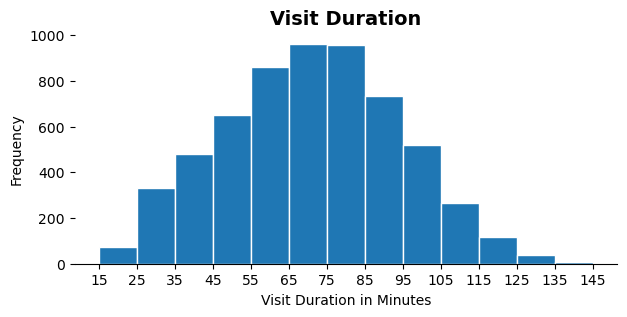

In [33]:
plt.figure(figsize=(7,3))
min_val = data['total_visit_duration_minutes'].min()
max_val = data['total_visit_duration_minutes'].max()
bins = np.arange(min_val-0.1,max_val+1.9, 10)
plt.hist(data=data, x='total_visit_duration_minutes',bins=bins, edgecolor='white')
plt.title("Visit Duration", fontsize=14, fontweight='bold')
plt.xlabel('Visit Duration in Minutes')
plt.ylabel('Frequency')
plt.xticks(bins)
sns.despine(left=True, top=True, right=True)
plt.show()

### BIVARIATE EDA

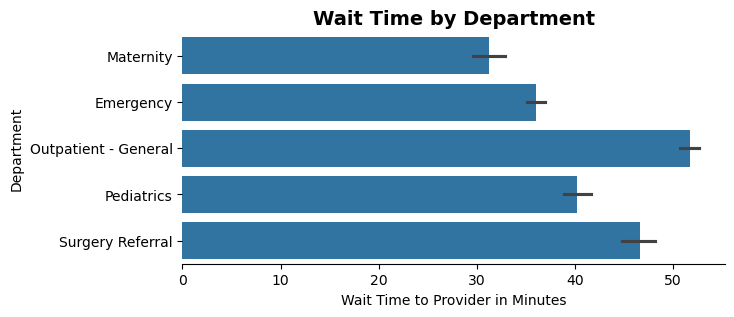

In [34]:
# department with the longest wait time
plt.figure(figsize=(7,3))
sns.barplot(data=data, x='wait_time_to_provider_minutes', y='department')
plt.title('Wait Time by Department', fontsize=14, fontweight='bold')
plt.ylabel('Department')
plt.xlabel('Wait Time to Provider in Minutes')
sns.despine(left=True, top=True, right=True)
plt.show()

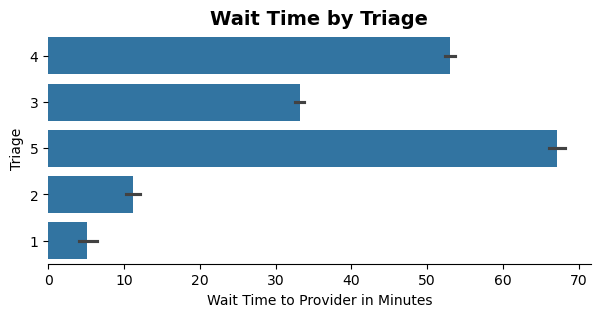

In [35]:
plt.figure(figsize=(7,3))
sns.barplot(data=data, x='wait_time_to_provider_minutes', y='triage_priority')
plt.title('Wait Time by Triage', fontsize=14, fontweight='bold')
plt.ylabel('Triage')
plt.xlabel('Wait Time to Provider in Minutes')
sns.despine(left=True, top=True, right=True)
plt.show()

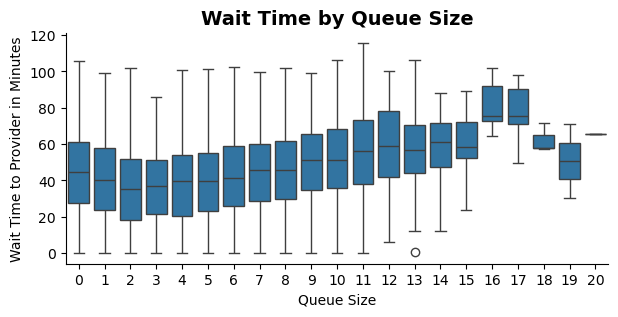

In [36]:
plt.figure(figsize=(7,3))
sns.boxplot(data=data, y='wait_time_to_provider_minutes', x='patients_in_queue_at_arrival')
plt.title('Wait Time by Queue Size', fontsize=14, fontweight='bold')
plt.xlabel('Queue Size')
plt.ylabel('Wait Time to Provider in Minutes')
sns.despine(top=True, right=True)
plt.show()

##### The long whiskers across almost all columns show that wait times have a wide spread. Even when the queue is small, some patients still experience long outliers, pointing to bottlenecks elsewhere in the hospital's operations such as bed availability or physician documentation delays, rather than just queue congestion alone.

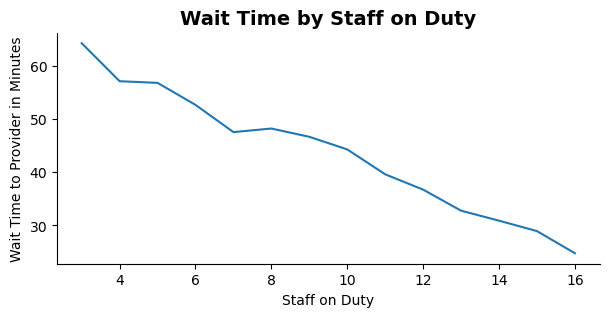

In [37]:
plt.figure(figsize=(7,3))
sns.lineplot(data=data, y='wait_time_to_provider_minutes', x='staff_on_duty', errorbar=None)
plt.title('Wait Time by Staff on Duty', fontsize=14, fontweight='bold')
plt.xlabel('Staff on Duty')
plt.ylabel('Wait Time to Provider in Minutes')
sns.despine(top=True, right=True)
plt.show()

##### As the number of staff on duty increases from 3 up to 16, the average wait time drops sharply from around 65 minutes down to roughly 25 minutes. This shows that scaling up staff may directly mitigate operational bottlenecks.

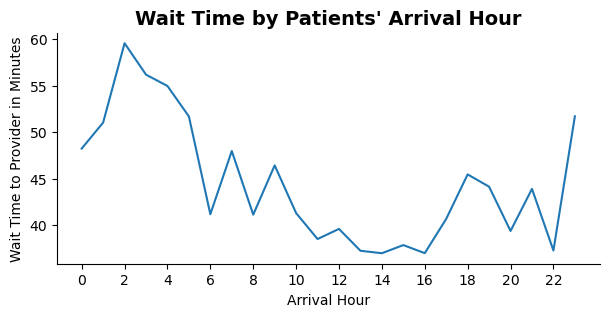

In [38]:
plt.figure(figsize=(7,3))
sns.lineplot(data=data, y='wait_time_to_provider_minutes', x='arrival_hour', errorbar=None)
plt.title("Wait Time by Patients' Arrival Hour", fontsize=14, fontweight='bold')
plt.xlabel('Arrival Hour')
plt.ylabel('Wait Time to Provider in Minutes')
plt.xticks(np.arange(0, 24, 2))
sns.despine(top=True, right=True)
plt.show()

##### Patients' wait time surge dramatically around 2am, climbing close to 60 minutes before experiencing a sharp drop. Wait times vary considerably across the 24-hour cycle, identfying specific high-demand operational windows versus lulls in the schedule.

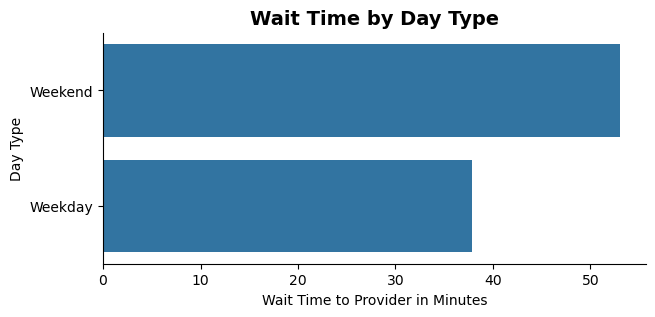

In [39]:
plt.figure(figsize=(7,3))
sns.barplot(data=data, x='wait_time_to_provider_minutes', y='day_type', errorbar=None)
plt.title("Wait Time by Day Type", fontsize=14, fontweight='bold')
plt.ylabel('Day Type')
plt.xlabel('Wait Time to Provider in Minutes')
sns.despine(top=True, right=True)
plt.show()

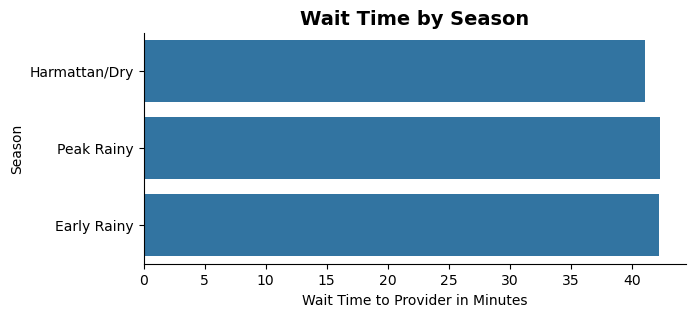

In [40]:
plt.figure(figsize=(7,3))
sns.barplot(data=data, x='wait_time_to_provider_minutes', y='season', errorbar=None)
plt.title("Wait Time by Season", fontsize=14, fontweight='bold')
plt.ylabel('Season')
plt.xlabel('Wait Time to Provider in Minutes')
sns.despine(top=True, right=True)
plt.show()

In [41]:
#investigating relationships between queue size/staffing and wait time
data[['wait_time_to_provider_minutes', 'patients_in_queue_at_arrival', 'staff_on_duty']].corr(method='spearman')

,wait_time_to_provider_minutes,patients_in_queue_at_arrival,staff_on_duty
wait_time_to_provider_minutes,1.000000,0.184663,-0.277957
patients_in_queue_at_arrival,0.184663,1.000000,0.171779
staff_on_duty,-0.277957,0.171779,1.000000


<Axes: >

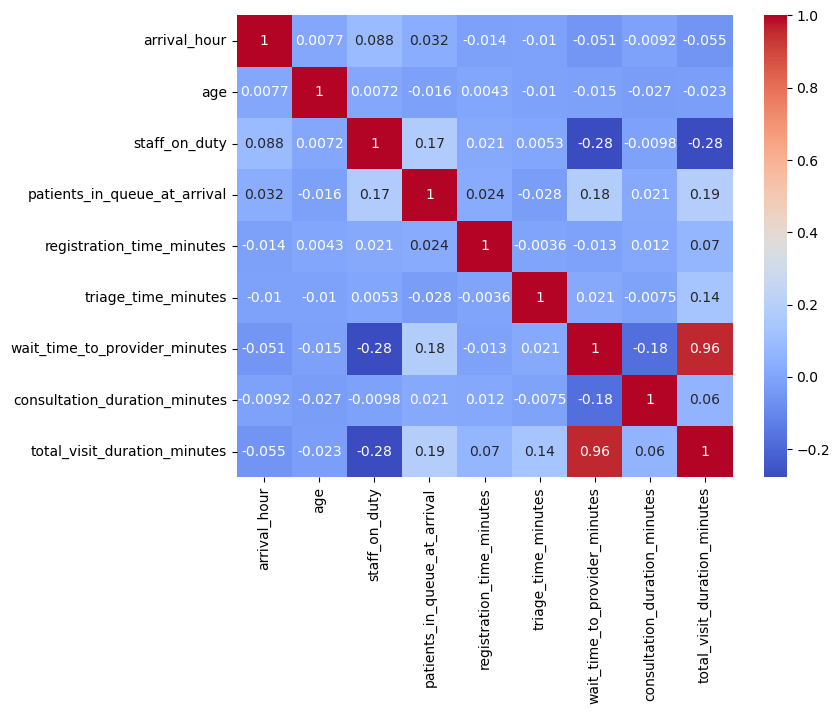

In [42]:
corr = data.corr(method='spearman', numeric_only=True)
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm')

##### Because consultation duration (0.06) and initial intake processes like registration (0.07) and triage (0.14) show very weak correlations with total time, provider wait time exhibits the strongest linear association with overall visit duration.

##### To improve throughput, reducing provider wait times should be the primary goal.

##### The number of staff on duty shows a moderate negative correlation (-0.28) with provider wait time while the number of patients on queue at arrival has a mild positive correlation (0.19). While arriving to a crowded queue is correlated with an increase in wait time, staffing levels show a stronger inverse association with provider wait times.

##### Finally, the time taken to register and triage have near zero correlations with provider wait time. This implies that minor delays at the front desk or triage counter may not significantly ripple into major downstream wait times. 

In [43]:
#exporting cleaned data for further analysis
data.to_excel('data.xlsx', index=False)

In [44]:
data_model = data.drop(columns=["patient_id", "day_type", "chief_complaint", "triage_time_minutes", "registration_time_minutes", "consultation_duration_minutes", "total_visit_duration_minutes"])

In [45]:
def get_time_of_day(hour):
    if 5<= hour < 12:
        return 'Morning'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 21:
        return 'Evening'
    else:
        return 'Night'
data_model['time_of_day'] = data_model['arrival_hour'].apply(get_time_of_day)

In [46]:
data_model = data_model.drop(columns=['visit_date', 'arrival_time', 'arrival_hour'])
data_model

,day_of_week,season,department,triage_priority,age,gender,staff_on_duty,patients_in_queue_at_arrival,wait_time_to_provider_minutes,time_of_day
0,Saturday,Harmattan/Dry,Maternity,4,9,Male,9,6,46.8,Afternoon
1,Wednesday,Peak Rainy,Maternity,4,43,Male,8,3,33.1,Night
2,Monday,Peak Rainy,Maternity,4,17,Male,12,3,25.6,Afternoon
3,Saturday,Early Rainy,Emergency,4,6,Male,10,4,47.2,Morning
4,Friday,Peak Rainy,Outpatient - General,4,23,Female,11,2,56.4,Evening
...,...,...,...,...,...,...,...,...,...,...
5995,Friday,Peak Rainy,Pediatrics,4,25,Male,11,6,49.6,Morning
5996,Saturday,Early Rainy,Outpatient - General,4,52,Male,3,6,84.4,Morning
5997,Wednesday,Peak Rainy,Emergency,4,24,Female,11,9,60.4,Morning
5998,Sunday,Peak Rainy,Surgery Referral,2,19,Male,7,2,2.1,Morning


In [47]:
#separating features (x) from target (y)
x = data_model.drop(columns=['wait_time_to_provider_minutes'])
y = data_model['wait_time_to_provider_minutes']

In [48]:
#one-hot encoding categorical columns
x_encoded = pd.get_dummies(x, drop_first=True, dtype=int)
x_encoded

,age,staff_on_duty,patients_in_queue_at_arrival,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday,season_Harmattan/Dry,...,department_Pediatrics,department_Surgery Referral,triage_priority_2,triage_priority_3,triage_priority_4,triage_priority_5,gender_Male,time_of_day_Evening,time_of_day_Morning,time_of_day_Night
0,9,9,6,0,1,0,0,0,0,1,...,0,0,0,0,1,0,1,0,0,0
1,43,8,3,0,0,0,0,0,1,0,...,0,0,0,0,1,0,1,0,0,1
2,17,12,3,1,0,0,0,0,0,0,...,0,0,0,0,1,0,1,0,0,0
3,6,10,4,0,1,0,0,0,0,0,...,0,0,0,0,1,0,1,0,1,0
4,23,11,2,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,25,11,6,0,0,0,0,0,0,0,...,1,0,0,0,1,0,1,0,1,0
5996,52,3,6,0,1,0,0,0,0,0,...,0,0,0,0,1,0,1,0,1,0
5997,24,11,9,0,0,0,0,0,1,0,...,0,0,0,0,1,0,0,0,1,0
5998,19,7,2,0,0,1,0,0,0,0,...,0,1,1,0,0,0,1,0,1,0


In [49]:
#checking for missing values and non-integer values
x_encoded.isnull().sum()

age                                0
staff_on_duty                      0
patients_in_queue_at_arrival       0
day_of_week_Monday                 0
day_of_week_Saturday               0
day_of_week_Sunday                 0
day_of_week_Thursday               0
day_of_week_Tuesday                0
day_of_week_Wednesday              0
season_Harmattan/Dry               0
season_Peak Rainy                  0
department_Maternity               0
department_Outpatient - General    0
department_Pediatrics              0
department_Surgery Referral        0
triage_priority_2                  0
triage_priority_3                  0
triage_priority_4                  0
triage_priority_5                  0
gender_Male                        0
time_of_day_Evening                0
time_of_day_Morning                0
time_of_day_Night                  0
dtype: int64

In [50]:
x_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 23 columns):
 #   Column                           Non-Null Count  Dtype
---  ------                           --------------  -----
 0   age                              6000 non-null   int64
 1   staff_on_duty                    6000 non-null   int64
 2   patients_in_queue_at_arrival     6000 non-null   int64
 3   day_of_week_Monday               6000 non-null   int32
 4   day_of_week_Saturday             6000 non-null   int32
 5   day_of_week_Sunday               6000 non-null   int32
 6   day_of_week_Thursday             6000 non-null   int32
 7   day_of_week_Tuesday              6000 non-null   int32
 8   day_of_week_Wednesday            6000 non-null   int32
 9   season_Harmattan/Dry             6000 non-null   int32
 10  season_Peak Rainy                6000 non-null   int32
 11  department_Maternity             6000 non-null   int32
 12  department_Outpatient - General  6000 non-null  

In [51]:
#splitting train and test data
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_encoded, y, test_size=0.2, random_state=42)

In [52]:
#scaling features
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [53]:
#training the model
from sklearn.linear_model import LinearRegression
reg = LinearRegression()
reg.fit(x_train_scaled, y_train)

LinearRegression()

In [54]:
#predicting and evaluating the model
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
y_pred = reg.predict(x_test_scaled)
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", root_mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 7.2563285072962636
RMSE: 9.038639007321732
R2 Score: 0.8450051885349901


In [55]:
#Inspecting the model's coefficients to identify the driving factor(s)
coef_df = pd.DataFrame({'Feature': x_encoded.columns, 'Coefficient': reg.coef_})
coef_df.sort_values(by='Coefficient', ascending=False)

,Feature,Coefficient
17,triage_priority_4,23.023640
18,triage_priority_5,22.421243
16,triage_priority_3,13.421867
12,department_Outpatient - General,6.845802
2,patients_in_queue_at_arrival,5.306220
4,day_of_week_Saturday,3.053672
5,day_of_week_Sunday,2.855714
14,department_Surgery Referral,2.809691
15,triage_priority_2,2.402222
13,department_Pediatrics,1.633281


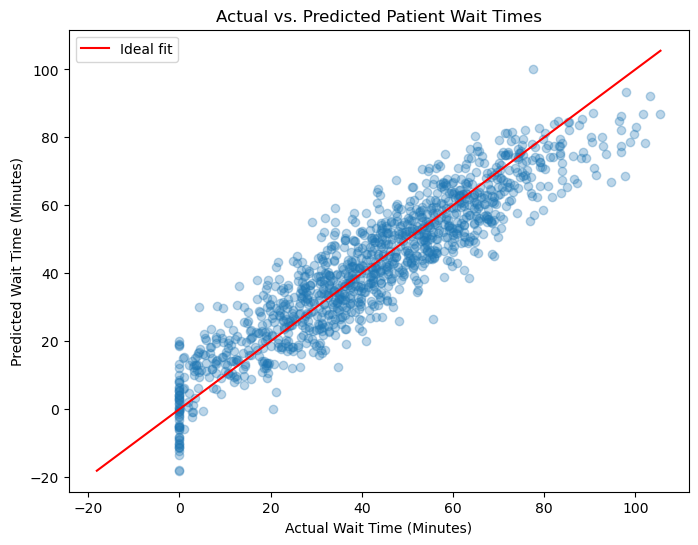

In [56]:
#plotting the regression model
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred, alpha=0.3)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', label='Ideal fit')
plt.xlabel("Actual Wait Time (Minutes)")
plt.ylabel("Predicted Wait Time (Minutes)")
plt.title("Actual vs. Predicted Patient Wait Times")
plt.legend()
plt.show()

There are negative predicted values. This should not be. Let's try random forest and decision tree.

In [57]:
np.sum(y_pred < 0)

33

In [58]:
x_encoded.describe()

,age,staff_on_duty,patients_in_queue_at_arrival,day_of_week_Monday,day_of_week_Saturday,day_of_week_Sunday,day_of_week_Thursday,day_of_week_Tuesday,day_of_week_Wednesday,season_Harmattan/Dry,...,department_Pediatrics,department_Surgery Referral,triage_priority_2,triage_priority_3,triage_priority_4,triage_priority_5,gender_Male,time_of_day_Evening,time_of_day_Morning,time_of_day_Night
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,...,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,33.718500,10.165333,5.270167,0.153333,0.137833,0.137000,0.142167,0.141667,0.139167,0.222000,...,0.145167,0.104833,0.113500,0.349333,0.355500,0.151833,0.500333,0.269667,0.373000,0.112833
std,21.963591,2.357242,3.155604,0.360339,0.344754,0.343876,0.349250,0.348737,0.346149,0.415626,...,0.352298,0.306364,0.317229,0.476799,0.478704,0.358889,0.500042,0.443824,0.483642,0.316415
min,0.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,17.000000,9.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,29.000000,11.000000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,46.000000,12.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000
max,95.000000,16.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [59]:
# Decision Tree 
from sklearn.tree import DecisionTreeRegressor
dt_model = DecisionTreeRegressor(max_depth=6, random_state=42)
dt_model.fit(x_train, y_train)
y_pred_dt = dt_model.predict(x_test)
print("MAE:", mean_absolute_error(y_test, y_pred_dt))
print("RMSE:", root_mean_squared_error(y_test, y_pred_dt))
print("R2 Score:", r2_score(y_test, y_pred_dt))

MAE: 9.358601871047863
RMSE: 11.775885637807079
R2 Score: 0.7369136983973339


In [60]:
np.sum(y_pred_dt < 0)

0

In [61]:
#Random Forest
from sklearn.ensemble import RandomForestRegressor
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train)
y_pred_rf = rf_model.predict(x_test)
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("RMSE:", root_mean_squared_error(y_test, y_pred_rf))
print("R2 Score:", r2_score(y_test, y_pred_rf))

MAE: 7.574555999999999
RMSE: 9.590919658797064
R2 Score: 0.8254854735448396


In [62]:
np.sum(y_pred_rf < 0)

0

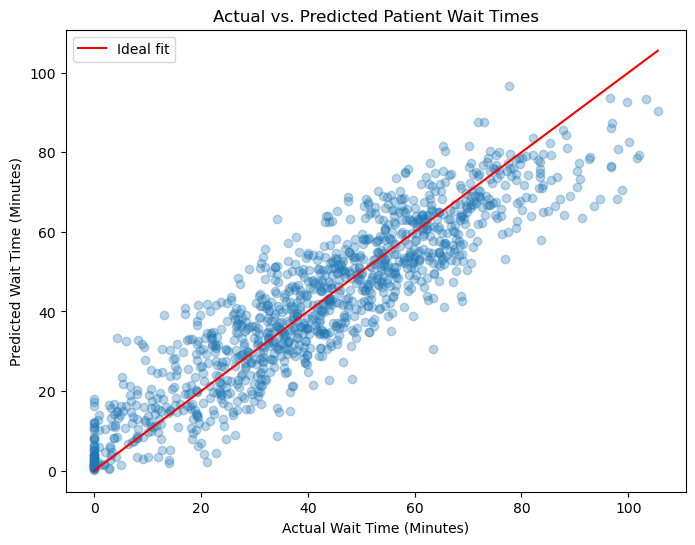

In [63]:
#plotting the regression model (RANDOM FOREST)
plt.figure(figsize=(8,6))
plt.scatter(y_test, y_pred_rf, alpha=0.3)
min_val = min(y_test.min(), y_pred_rf.min())
max_val = max(y_test.max(), y_pred_rf.max())
plt.plot([min_val, max_val], [min_val, max_val], color='red', label='Ideal fit')
plt.xlabel("Actual Wait Time (Minutes)")
plt.ylabel("Predicted Wait Time (Minutes)")
plt.title("Actual vs. Predicted Patient Wait Times")
plt.legend()
plt.savefig(r'C:\Users\user\OneDrive\Documents\ZION TECH HUB CAPSTONE\rf_regression_model.png', dpi=300, bbox_inches='tight')
plt.show()

Random Forest Regressor predicts no negative wait time to see provider and has a better R2 score compared with decision tree regressor, although it is lower than linear regressor. Hence, the best model is the random forest regressor.

In [64]:
fi_df = pd.DataFrame({'Feature': x_train.columns, 'Importance':rf_model.feature_importances_}).sort_values(by='Importance', ascending=False)
fi_df

,Feature,Importance
15,triage_priority_2,0.210690
16,triage_priority_3,0.171575
17,triage_priority_4,0.135719
1,staff_on_duty,0.099200
2,patients_in_queue_at_arrival,0.078756
18,triage_priority_5,0.078472
12,department_Outpatient - General,0.072009
0,age,0.046236
4,day_of_week_Saturday,0.016720
5,day_of_week_Sunday,0.016596


##### Triage_priority sit at the absolute top of the ranking with the highest importance scores (over 0.5 combined). Patient acuity level is by far the most dominant factor dictating how long a patient waits. This confirms that the emergency department's triage system is heavily influencing scheduling and resource allocation (prioritizing the most critical cases, while lower-priority patients experience structured waits).

##### staff on duty and patients in queue rank right behind triage_priority. Hospital capacity and staffing levels have a massive measurable impact on patient delays. When queue is crowded upon arrival or staffing is constrained, wait times surge. This gives management a direct operational lever: adjusting staffing levels can actively shorten wait times.

##### Demographic features like age and gender fall much lower down the list. Personal demographics play very little role in determining wait times. The system treats patients based on medical urgency and operational load rather than personal background, which is an indicator of fairness and equity in the clinical workflow.

##### Days of the week and times of the day have very low importance scores (below 0.02). While time/day affects volume slightly, it is secondary compared to real-time congestion and clinical urgency.